In [1]:
!pip install -q librosa soundfile numpy scikit-learn matplotlib seaborn tqdm transformers

print("All libraries installed.")


All libraries installed.


In [2]:
import os
import numpy as np
import pandas as pd
import librosa
from tqdm import tqdm
import torch

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import seaborn as sns

from transformers import Wav2Vec2Processor, Wav2Vec2Model

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)


Using device: cuda


In [3]:
import urllib.request
import zipfile

dataset_url = "https://zenodo.org/records/1188976/files/Audio_Speech_Actors_01-24.zip"
zip_path = "ravdess.zip"
root_dir = "/content/RAVDESS"

if not os.path.exists(root_dir):
    print("Downloading RAVDESS...")
    urllib.request.urlretrieve(dataset_url, zip_path)
    print("Download complete. Extracting...")

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall("RAVDESS")

    print("Extracted to:", root_dir)
else:
    print("RAVDESS already exists at", root_dir)


Download complete. Extracting...
Extracted to: /content/RAVDESS


In [4]:
emotion_labels = {
    "01": "neutral",
    "02": "calm",
    "03": "happy",
    "04": "sad",
    "05": "angry",
    "06": "fearful",
    "07": "disgust",
    "08": "surprised"
}

rows = []

for actor_folder in sorted(os.listdir(root_dir)):
    actor_path = os.path.join(root_dir, actor_folder)
    if not os.path.isdir(actor_path):
        continue

    for file in os.listdir(actor_path):
        if not file.endswith(".wav"):
            continue

        parts = file.split("-")
        if len(parts) != 7:
            continue  # sanity

        modality      = parts[0]  # 03
        vocal_channel = parts[1]  # 01 (speech)
        emotion_code  = parts[2]  # 01-08
        intensity     = parts[3]  # 01 (low) or 02 (high)
        statement     = parts[4]
        repetition    = parts[5]
        actor_id      = parts[6].replace(".wav", "")  # "01".."24"

        rows.append({
            "audio_file": os.path.join(actor_path, file),
            "emotion_label": emotion_labels[emotion_code],
            "intensity_label": "low" if intensity == "01" else "high",
            "actor_id": actor_id
        })

df = pd.DataFrame(rows)
df.to_csv("ravdess_metadata.csv", index=False)
print("Metadata saved as ravdess_metadata.csv")
df.head()


Metadata saved as ravdess_metadata.csv


,audio_file,emotion_label,intensity_label,actor_id
0,/content/RAVDESS/Actor_01/03-01-04-02-02-01-01...,sad,high,01
1,/content/RAVDESS/Actor_01/03-01-07-01-02-01-01...,disgust,low,01
2,/content/RAVDESS/Actor_01/03-01-06-02-02-01-01...,fearful,high,01
3,/content/RAVDESS/Actor_01/03-01-03-02-02-02-01...,happy,high,01
4,/content/RAVDESS/Actor_01/03-01-05-01-02-02-01...,angry,low,01


In [5]:
df = pd.read_csv("ravdess_metadata.csv")
print(df.shape)
df.head()


(1440, 4)


,audio_file,emotion_label,intensity_label,actor_id
0,/content/RAVDESS/Actor_01/03-01-04-02-02-01-01...,sad,high,1
1,/content/RAVDESS/Actor_01/03-01-07-01-02-01-01...,disgust,low,1
2,/content/RAVDESS/Actor_01/03-01-06-02-02-01-01...,fearful,high,1
3,/content/RAVDESS/Actor_01/03-01-03-02-02-02-01...,happy,high,1
4,/content/RAVDESS/Actor_01/03-01-05-01-02-02-01...,angry,low,1


In [6]:
# Pretrained base Wav2Vec2
MODEL_NAME = "facebook/wav2vec2-base"

processor = Wav2Vec2Processor.from_pretrained(MODEL_NAME)
wav2vec_model = Wav2Vec2Model.from_pretrained(MODEL_NAME).to(device)
wav2vec_model.eval()

print("Wav2Vec2 loaded.")


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.12/dist-packages/transformers/configuration_utils.py:364: UserWarning: Passing `gradient_checkpointing` to a config initialization is deprecated and will be removed in v5 Transformers. Using `model.gradient_checkpointing_enable()` instead, or if you are using the `Trainer` API, pass `gradient_checkpointing=True` in your `TrainingArguments`.
  warnings.warn(


...

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


pytorch_model.bin:   0%|          | 0.00/380M [00:00<?, ?B/s]

Some weights of Wav2Vec2Model were not initialized from the model checkpoint at facebook/wav2vec2-base and are newly initialized: ['wav2vec2.encoder.pos_conv_embed.conv.parametrizations.weight.original0', 'wav2vec2.encoder.pos_conv_embed.conv.parametrizations.weight.original1']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Wav2Vec2 loaded.


In [7]:
TARGET_SR = 16000  # Wav2Vec2 expects 16kHz

@torch.no_grad()
def extract_wav2vec2_embedding(path):
    # Load audio
    audio, sr = librosa.load(path, sr=TARGET_SR)
    # Convert to model inputs
    inputs = processor(
        audio,
        sampling_rate=TARGET_SR,
        return_tensors="pt",
        padding=True
    )
    input_values = inputs["input_values"].to(device)  # (1, T)

    # Forward pass
    outputs = wav2vec_model(input_values)
    hidden_states = outputs.last_hidden_state  # (1, T, 768)

    # Mean pool over time → (768,)
    embedding = hidden_states.mean(dim=1).squeeze(0).cpu().numpy()
    return embedding


In [8]:
X = []
y_emotion = []
y_intensity = []

print("🎧 Extracting Wav2Vec2 embeddings for all audio files...")

for idx, row in tqdm(df.iterrows(), total=len(df)):
    emb = extract_wav2vec2_embedding(row["audio_file"])
    X.append(emb)
    y_emotion.append(row["emotion_label"])
    y_intensity.append(row["intensity_label"])

X = np.array(X)
y_emotion = np.array(y_emotion)
y_intensity = np.array(y_intensity)

print("✅ Feature extraction done. Shape:", X.shape)


🎧 Extracting Wav2Vec2 embeddings for all audio files...


100%|██████████| 1440/1440 [00:55<00:00, 25.96it/s]

✅ Feature extraction done. Shape: (1440, 768)


In [9]:
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X, y_emotion, test_size=0.2, random_state=42, stratify=y_emotion
)

X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(
    X, y_intensity, test_size=0.2, random_state=42, stratify=y_intensity
)

print("Emotion train/test:", X_train_e.shape, X_test_e.shape)
print("Intensity train/test:", X_train_i.shape, X_test_i.shape)


Emotion train/test: (1152, 768) (288, 768)
Intensity train/test: (1152, 768) (288, 768)


In [10]:
# Emotion classifier
emotion_clf = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=10.0, gamma="scale", class_weight="balanced")
)

# Intensity classifier
intensity_clf = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=5.0, gamma="scale", class_weight="balanced")
)

print("Training emotion classifier...")
emotion_clf.fit(X_train_e, y_train_e)

print("Training intensity classifier...")
intensity_clf.fit(X_train_i, y_train_i)

print("Training finished.")


Training emotion classifier...
Training intensity classifier...
Training finished.



Emotion Classification Report:
              precision    recall  f1-score   support

       angry       0.78      0.84      0.81        38
        calm       0.73      0.79      0.76        38
     disgust       0.79      0.79      0.79        38
     fearful       0.83      0.64      0.72        39
       happy       0.64      0.59      0.61        39
     neutral       0.65      0.68      0.67        19
         sad       0.51      0.63      0.56        38
   surprised       0.71      0.64      0.68        39

    accuracy                           0.70       288
   macro avg       0.71      0.70      0.70       288
weighted avg       0.71      0.70      0.70       288

Emotion Model Accuracy: 0.701


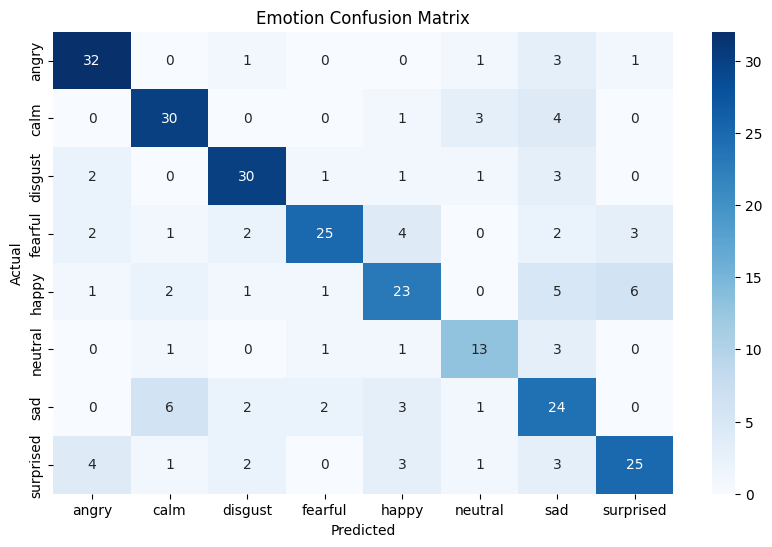


Intensity Classification Report:
              precision    recall  f1-score   support

        high       0.81      0.67      0.73       134
         low       0.75      0.86      0.80       154

    accuracy                           0.77       288
   macro avg       0.78      0.77      0.77       288
weighted avg       0.78      0.77      0.77       288

Intensity Model Accuracy: 0.774


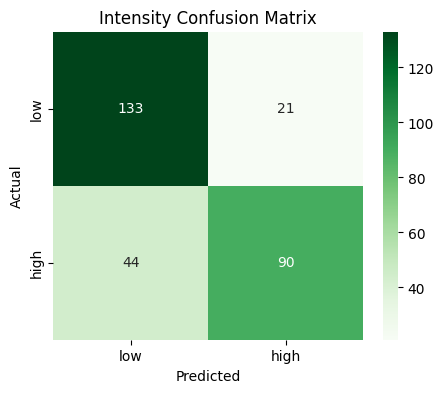

In [11]:
# ---------- Emotion ----------
y_pred_e = emotion_clf.predict(X_test_e)
emotion_acc = accuracy_score(y_test_e, y_pred_e)

print("\nEmotion Classification Report:")
print(classification_report(y_test_e, y_pred_e))
print("Emotion Model Accuracy:", round(emotion_acc, 3))

# Confusion matrix (emotion)
plt.figure(figsize=(10,6))
cm_e = confusion_matrix(y_test_e, y_pred_e, labels=sorted(np.unique(y_emotion)))
sns.heatmap(
    cm_e,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(np.unique(y_emotion)),
    yticklabels=sorted(np.unique(y_emotion))
)
plt.title("Emotion Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ---------- Intensity ----------
y_pred_i = intensity_clf.predict(X_test_i)
intensity_acc = accuracy_score(y_test_i, y_pred_i)

print("\nIntensity Classification Report:")
print(classification_report(y_test_i, y_pred_i))
print("Intensity Model Accuracy:", round(intensity_acc, 3))

# Confusion matrix (intensity)
plt.figure(figsize=(5,4))
cm_i = confusion_matrix(y_test_i, y_pred_i, labels=["low", "high"])
sns.heatmap(
    cm_i,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["low", "high"],
    yticklabels=["low", "high"]
)
plt.title("Intensity Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [12]:
pred_rows = []

for idx, row in tqdm(df.iterrows(), total=len(df)):
    audio_file = row["audio_file"]
    actor_id = row["actor_id"]

    emb = X[idx]  # we already computed embeddings in order
    emb = emb.reshape(1, -1)

    pred_emotion = emotion_clf.predict(emb)[0]
    pred_intensity = intensity_clf.predict(emb)[0]

    pred_rows.append({
        "audio_file": audio_file,
        "emotion_label": pred_emotion,      # model output
        "intensity_label": pred_intensity,  # model output
        "actor_id": actor_id
    })

pred_df = pd.DataFrame(pred_rows)
pred_df.to_csv("ravdess_full_predictions.csv", index=False)

print("Saved predictions to ravdess_full_predictions.csv")
pred_df.head()


100%|██████████| 1440/1440 [00:03<00:00, 380.63it/s]

Saved predictions to ravdess_full_predictions.csv


,audio_file,emotion_label,intensity_label,actor_id
0,/content/RAVDESS/Actor_01/03-01-04-02-02-01-01...,sad,high,1
1,/content/RAVDESS/Actor_01/03-01-07-01-02-01-01...,disgust,low,1
2,/content/RAVDESS/Actor_01/03-01-06-02-02-01-01...,fearful,high,1
3,/content/RAVDESS/Actor_01/03-01-03-02-02-02-01...,happy,high,1
4,/content/RAVDESS/Actor_01/03-01-05-01-02-02-01...,angry,low,1


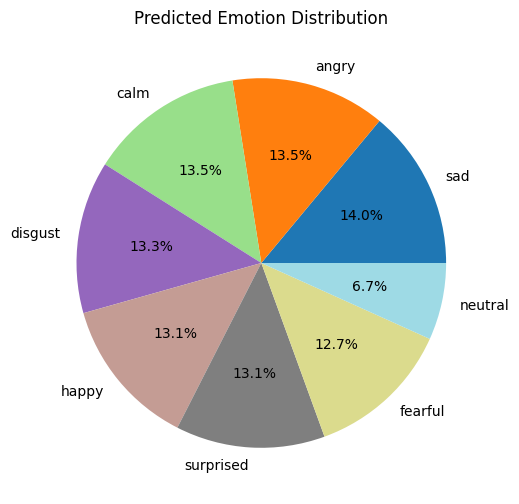

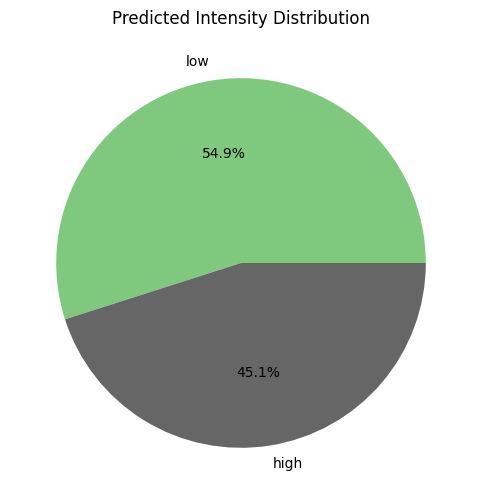

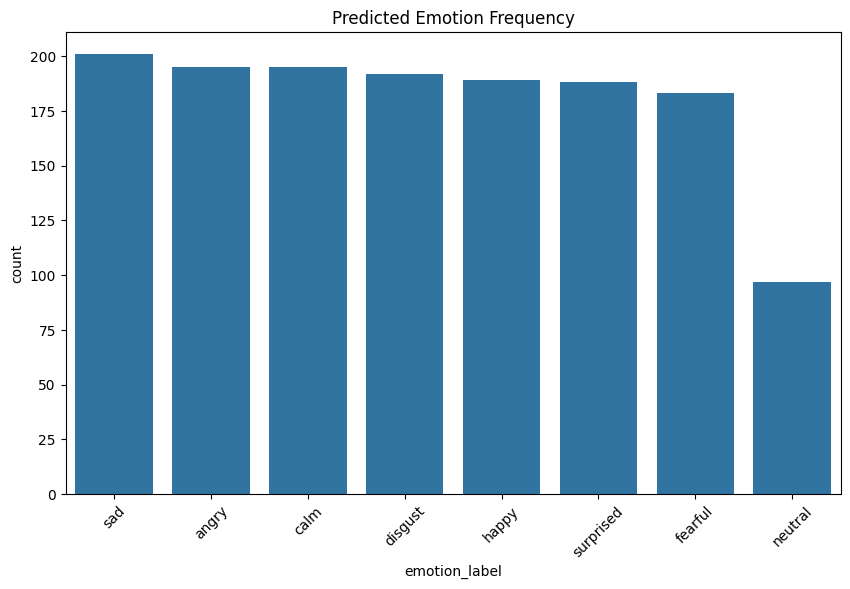

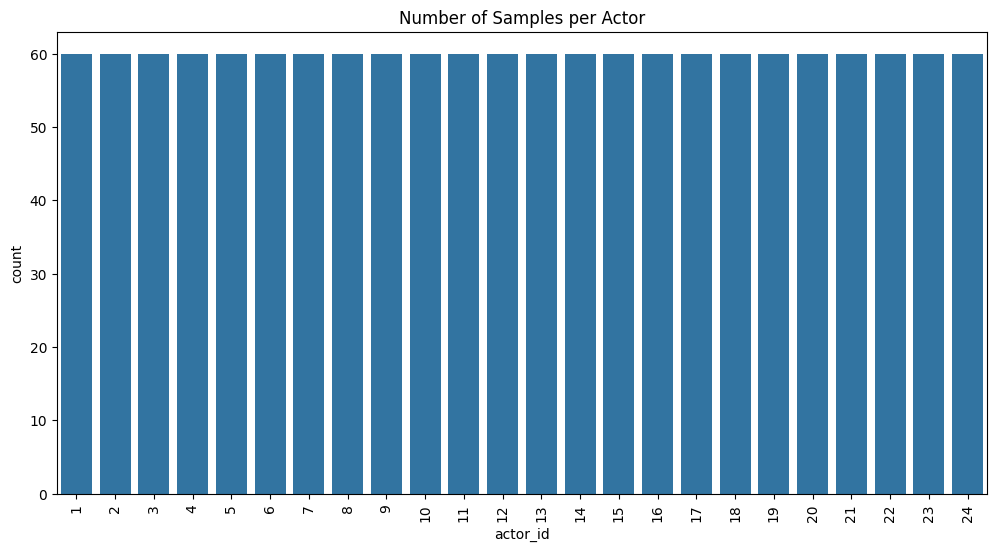

In [13]:
viz_df = pd.read_csv("ravdess_full_predictions.csv")

# ---------- Emotion distribution (Pie) ----------
plt.figure(figsize=(8,6))
viz_df["emotion_label"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    colormap="tab20"
)
plt.title("Predicted Emotion Distribution")
plt.ylabel("")
plt.show()

# ---------- Intensity distribution (Pie) ----------
plt.figure(figsize=(6,6))
viz_df["intensity_label"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    colormap="Accent"
)
plt.title("Predicted Intensity Distribution")
plt.ylabel("")
plt.show()

# ---------- Emotion frequency (Bar) ----------
plt.figure(figsize=(10,6))
sns.countplot(data=viz_df, x="emotion_label", order=viz_df["emotion_label"].value_counts().index)
plt.title("Predicted Emotion Frequency")
plt.xticks(rotation=45)
plt.show()

# ---------- Samples per actor (Bar) ----------
plt.figure(figsize=(12,6))
sns.countplot(data=viz_df, x="actor_id", order=sorted(viz_df["actor_id"].unique()))
plt.title("Number of Samples per Actor")
plt.xticks(rotation=90)
plt.show()
